In [1]:
import numpy as np
import pandas as pa
import matplotlib.pyplot as plt
import seaborn as se 
import joblib
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score 
from sklearn.preprocessing import StandardScaler , PowerTransformer , MinMaxScaler , TargetEncoder
from tensorflow.keras.models import Sequential , load_model
from tensorflow.keras.layers import Dense , Normalization 
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf
import keras as ks

In [2]:
file = pa.read_csv('MLS_price_home.csv')
file.head()

,Location,CompIndex,CompBenchmark,CompYoYChange,SFDetachIndex,SFDetachBenchmark,SFDetachYoYChange,SFAttachIndex,SFAttachBenchmark,SFAttachYoYChange,THouseIndex,THouseBenchmark,THouseYoYChange,ApartIndex,ApartBenchmark,ApartYoYChange,Date
0,Adjala-Tosorontio,143.7,510000,12.00,143.7,510000,12.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7/1/2015
1,Adjala-Tosorontio,140.8,499700,13.82,140.8,499700,13.82,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8/1/2015
2,Adjala-Tosorontio,142.7,506400,15.83,142.7,506400,15.83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9/1/2015
3,Adjala-Tosorontio,138.4,491100,11.08,138.4,491100,11.08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10/1/2015
4,Adjala-Tosorontio,145.4,516000,16.51,145.4,516000,16.51,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11/1/2015


In [3]:
file.info()

<class 'pandas.DataFrame'>
RangeIndex: 5076 entries, 0 to 5075
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Location           5076 non-null   str    
 1   CompIndex          5076 non-null   float64
 2   CompBenchmark      5076 non-null   int64  
 3   CompYoYChange      5076 non-null   float64
 4   SFDetachIndex      5076 non-null   float64
 5   SFDetachBenchmark  5076 non-null   int64  
 6   SFDetachYoYChange  5075 non-null   float64
 7   SFAttachIndex      4949 non-null   float64
 8   SFAttachBenchmark  4949 non-null   float64
 9   SFAttachYoYChange  4951 non-null   float64
 10  THouseIndex        3803 non-null   float64
 11  THouseBenchmark    3803 non-null   float64
 12  THouseYoYChange    3804 non-null   float64
 13  ApartIndex         4010 non-null   float64
 14  ApartBenchmark     4010 non-null   float64
 15  ApartYoYChange     4008 non-null   float64
 16  Date               5076 non-null   

In [4]:
file.describe()

,CompIndex,CompBenchmark,CompYoYChange,SFDetachIndex,SFDetachBenchmark,SFDetachYoYChange,SFAttachIndex,SFAttachBenchmark,SFAttachYoYChange,THouseIndex,THouseBenchmark,THouseYoYChange,ApartIndex,ApartBenchmark,ApartYoYChange
count,5076.000000,5.076000e+03,5076.000000,5076.000000,5.076000e+03,5075.000000,4949.000000,4.949000e+03,4951.000000,3803.000000,3.803000e+03,3804.000000,4010.000000,4.010000e+03,4008.000000
mean,244.871592,7.720499e+05,10.222695,246.021277,9.481001e+05,9.329878,247.290139,7.182842e+05,9.311238,245.168393,5.829440e+05,9.466312,236.428279,4.838220e+05,11.521093
std,41.374120,2.725882e+05,9.186082,41.829704,3.765865e+05,10.411804,43.124667,2.433777e+05,10.105563,55.364090,2.212504e+05,14.473397,52.340839,1.457593e+05,9.079515
min,135.000000,2.570000e+05,-19.580000,126.000000,2.591000e+05,-21.320000,137.200000,2.733000e+05,-100.000000,0.000000,0.000000e+00,-100.000000,106.000000,1.714000e+05,-10.600000
25%,217.600000,5.890000e+05,4.380000,220.300000,6.822000e+05,2.245000,220.700000,5.429000e+05,2.715000,210.500000,4.394500e+05,4.080000,196.625000,3.819250e+05,5.640000
50%,247.100000,7.265000e+05,9.390000,246.700000,8.734500e+05,8.540000,246.700000,6.716000e+05,8.760000,246.400000,5.550000e+05,9.630000,239.600000,4.776000e+05,9.740000
75%,270.500000,9.033000e+05,15.382500,272.000000,1.137150e+06,15.715000,269.900000,8.399000e+05,15.370000,278.300000,6.731000e+05,15.602500,272.200000,5.692500e+05,15.290000
max,409.900000,2.162900e+06,46.780000,415.600000,2.536900e+06,49.100000,709.000000,1.677200e+06,43.710000,466.800000,1.750500e+06,56.490000,395.300000,1.005500e+06,64.320000


In [5]:
file['Location'].value_counts()

Location
City of Toronto              138
Adjala-Tosorontio             69
Ajax                          69
Aurora                        69
Brampton                      69
                            ... 
Toronto E11                   54
EGswsiallimbury               41
Bradford West Gwillimbury     15
Essa                          15
GEswsiallimbury               13
Name: count, Length: 76, dtype: int64

In [6]:
file.loc[file['SFDetachYoYChange'].isna() , 'SFDetachYoYChange'] = file['SFDetachYoYChange'].median()
file.loc[file['SFAttachIndex'].isna() , 'SFAttachIndex'] = 0
file.loc[file['SFAttachBenchmark'].isna() , 'SFAttachBenchmark'] = 0
file.loc[file['SFAttachYoYChange'].isna() , 'SFAttachYoYChange'] = 0
file.loc[file['THouseIndex'].isna() , 'THouseIndex'] = 0
file.loc[file['THouseBenchmark'].isna() , 'THouseBenchmark'] = 0
file.loc[file['THouseYoYChange'].isna() , 'THouseYoYChange'] = 0
file.loc[file['ApartIndex'].isna() , 'ApartIndex'] = 0
file.loc[file['ApartBenchmark'].isna() , 'ApartBenchmark'] = 0
file.loc[file['ApartYoYChange'].isna() , 'ApartYoYChange'] = 0

In [7]:
x_date = [2015 if '2015' in i else 2016 if '2016' in i else 2017 if '2017' in i else 2018 if '2018' in i else 2019 if '2019' in i else 2020 if '2020' in i else 2021 for i in file['Date']] 

In [8]:
x_date[:40]

[2015,
 2015,
 2015,
 2015,
 2015,
 2015,
 2016,
 2016,
 2016,
 2016,
 2016,
 2016,
 2016,
 2016,
 2016,
 2016,
 2016,
 2016,
 2017,
 2017,
 2017,
 2017,
 2017,
 2017,
 2017,
 2017,
 2017,
 2017,
 2017,
 2017,
 2018,
 2018,
 2018,
 2018,
 2018,
 2018,
 2018,
 2018,
 2018,
 2018]

In [9]:
file['year'] = x_date

In [10]:
file['SFDetachBenchmark'] = file['SFDetachBenchmark'].astype('float')
file['CompBenchmark'] = file['CompBenchmark'].astype('float')
file['year'] = file['year'].astype('float')

In [11]:
file.head()

,Location,CompIndex,CompBenchmark,CompYoYChange,SFDetachIndex,SFDetachBenchmark,SFDetachYoYChange,SFAttachIndex,SFAttachBenchmark,SFAttachYoYChange,THouseIndex,THouseBenchmark,THouseYoYChange,ApartIndex,ApartBenchmark,ApartYoYChange,Date,year
0,Adjala-Tosorontio,143.7,510000.0,12.00,143.7,510000.0,12.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7/1/2015,2015.0
1,Adjala-Tosorontio,140.8,499700.0,13.82,140.8,499700.0,13.82,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8/1/2015,2015.0
2,Adjala-Tosorontio,142.7,506400.0,15.83,142.7,506400.0,15.83,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9/1/2015,2015.0
3,Adjala-Tosorontio,138.4,491100.0,11.08,138.4,491100.0,11.08,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10/1/2015,2015.0
4,Adjala-Tosorontio,145.4,516000.0,16.51,145.4,516000.0,16.51,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11/1/2015,2015.0


In [12]:
file.info()

<class 'pandas.DataFrame'>
RangeIndex: 5076 entries, 0 to 5075
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Location           5076 non-null   str    
 1   CompIndex          5076 non-null   float64
 2   CompBenchmark      5076 non-null   float64
 3   CompYoYChange      5076 non-null   float64
 4   SFDetachIndex      5076 non-null   float64
 5   SFDetachBenchmark  5076 non-null   float64
 6   SFDetachYoYChange  5076 non-null   float64
 7   SFAttachIndex      5076 non-null   float64
 8   SFAttachBenchmark  5076 non-null   float64
 9   SFAttachYoYChange  5076 non-null   float64
 10  THouseIndex        5076 non-null   float64
 11  THouseBenchmark    5076 non-null   float64
 12  THouseYoYChange    5076 non-null   float64
 13  ApartIndex         5076 non-null   float64
 14  ApartBenchmark     5076 non-null   float64
 15  ApartYoYChange     5076 non-null   float64
 16  Date               5076 non-null   

In [13]:
file['CompBenchmark'].describe()

count    5.076000e+03
mean     7.720499e+05
std      2.725882e+05
min      2.570000e+05
25%      5.890000e+05
50%      7.265000e+05
75%      9.033000e+05
max      2.162900e+06
Name: CompBenchmark, dtype: float64

In [14]:
file['CompBenchmark'].skew()

np.float64(1.431845022972192)

In [15]:
file['CompBenchmark_log'] = np.log1p(file['CompBenchmark'])
file['CompBenchmark_log'].skew()

np.float64(0.18559817516087662)

In [16]:
file.head()

,Location,CompIndex,CompBenchmark,CompYoYChange,SFDetachIndex,SFDetachBenchmark,SFDetachYoYChange,SFAttachIndex,SFAttachBenchmark,SFAttachYoYChange,THouseIndex,THouseBenchmark,THouseYoYChange,ApartIndex,ApartBenchmark,ApartYoYChange,Date,year,CompBenchmark_log
0,Adjala-Tosorontio,143.7,510000.0,12.00,143.7,510000.0,12.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7/1/2015,2015.0,13.142168
1,Adjala-Tosorontio,140.8,499700.0,13.82,140.8,499700.0,13.82,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8/1/2015,2015.0,13.121765
2,Adjala-Tosorontio,142.7,506400.0,15.83,142.7,506400.0,15.83,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9/1/2015,2015.0,13.135084
3,Adjala-Tosorontio,138.4,491100.0,11.08,138.4,491100.0,11.08,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10/1/2015,2015.0,13.104405
4,Adjala-Tosorontio,145.4,516000.0,16.51,145.4,516000.0,16.51,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11/1/2015,2015.0,13.153864


In [17]:
file = file.drop('Date',axis=1)

In [18]:
file.head()

,Location,CompIndex,CompBenchmark,CompYoYChange,SFDetachIndex,SFDetachBenchmark,SFDetachYoYChange,SFAttachIndex,SFAttachBenchmark,SFAttachYoYChange,THouseIndex,THouseBenchmark,THouseYoYChange,ApartIndex,ApartBenchmark,ApartYoYChange,year,CompBenchmark_log
0,Adjala-Tosorontio,143.7,510000.0,12.00,143.7,510000.0,12.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2015.0,13.142168
1,Adjala-Tosorontio,140.8,499700.0,13.82,140.8,499700.0,13.82,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2015.0,13.121765
2,Adjala-Tosorontio,142.7,506400.0,15.83,142.7,506400.0,15.83,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2015.0,13.135084
3,Adjala-Tosorontio,138.4,491100.0,11.08,138.4,491100.0,11.08,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2015.0,13.104405
4,Adjala-Tosorontio,145.4,516000.0,16.51,145.4,516000.0,16.51,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2015.0,13.153864


In [19]:

Y_train = file['CompBenchmark_log'].loc[(file['year'] >= 2015) & (file['year'] <= 2018)]
Y_test = file['CompBenchmark_log'].loc[file['year'] >= 2019] 

In [20]:
file = file.drop(['CompBenchmark_log','CompBenchmark'],axis=1)

In [21]:
X_train = file.loc[(file['year'] >= 2015) & (file['year'] <= 2018)]
X_test = file.loc[file['year'] >= 2019]

In [22]:
X_train

,Location,CompIndex,CompYoYChange,SFDetachIndex,SFDetachBenchmark,SFDetachYoYChange,SFAttachIndex,SFAttachBenchmark,SFAttachYoYChange,THouseIndex,THouseBenchmark,THouseYoYChange,ApartIndex,ApartBenchmark,ApartYoYChange,year
0,Adjala-Tosorontio,143.7,12.00,143.7,510000.0,12.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,2015.0
1,Adjala-Tosorontio,140.8,13.82,140.8,499700.0,13.82,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,2015.0
2,Adjala-Tosorontio,142.7,15.83,142.7,506400.0,15.83,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,2015.0
3,Adjala-Tosorontio,138.4,11.08,138.4,491100.0,11.08,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,2015.0
4,Adjala-Tosorontio,145.4,16.51,145.4,516000.0,16.51,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,2015.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5044,York Region,253.9,-6.52,258.3,982900.0,-7.88,253.8,734300.0,-7.37,239.3,614500.0,-4.66,222.7,488400.0,3.01,2018.0
5045,York Region,252.5,-4.82,256.6,976500.0,-6.18,254.0,734900.0,-5.58,239.6,615300.0,-0.91,220.8,484300.0,4.00,2018.0
5046,York Region,251.3,-4.70,255.1,970800.0,-6.14,253.0,732000.0,-5.42,236.8,608100.0,-0.29,221.0,484700.0,4.44,2018.0
5047,York Region,250.2,-3.88,254.2,967300.0,-5.18,251.3,727100.0,-4.63,232.5,597100.0,-0.81,221.6,486000.0,4.68,2018.0


In [23]:
X_test

,Location,CompIndex,CompYoYChange,SFDetachIndex,SFDetachBenchmark,SFDetachYoYChange,SFAttachIndex,SFAttachBenchmark,SFAttachYoYChange,THouseIndex,THouseBenchmark,THouseYoYChange,ApartIndex,ApartBenchmark,ApartYoYChange,year
42,Adjala-Tosorontio,214.4,-2.94,214.2,646100.0,-2.99,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,2019.0
43,Adjala-Tosorontio,218.6,0.60,218.4,658700.0,0.60,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,2019.0
44,Adjala-Tosorontio,224.4,-0.66,224.2,676200.0,-0.71,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,2019.0
45,Adjala-Tosorontio,222.4,0.50,222.4,670800.0,0.59,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,2019.0
46,Adjala-Tosorontio,226.5,1.62,226.5,683200.0,1.71,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,2019.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5071,York Region,287.0,11.76,292.0,1112000.0,12.65,293.2,847300.0,12.73,271.3,704100.0,11.28,252.2,562700.0,6.91,2020.0
5072,York Region,289.5,12.56,295.2,1124200.0,13.89,296.3,856200.0,13.66,270.4,701800.0,10.28,253.2,564900.0,6.84,2020.0
5073,York Region,294.9,13.34,301.7,1148900.0,15.20,302.9,875300.0,14.78,272.6,707500.0,10.14,254.7,568200.0,5.86,2021.0
5074,York Region,309.9,17.16,318.6,1213300.0,20.23,322.6,932200.0,20.15,280.7,728500.0,11.04,260.2,580500.0,5.39,2021.0


In [24]:
Y_train

0       13.142168
1       13.121765
2       13.135084
3       13.104405
4       13.153864
          ...    
5044    13.660728
5045    13.655226
5046    13.650519
5047    13.646027
5048    13.638058
Name: CompBenchmark_log, Length: 3108, dtype: float64

In [25]:
Y_test

42      13.377317
43      13.396658
44      13.422766
45      13.413840
46      13.432200
          ...    
5071    13.785362
5072    13.793981
5073    13.812507
5074    13.862109
5075    13.906905
Name: CompBenchmark_log, Length: 1968, dtype: float64

In [26]:
missing_cols = [
    'SFAttachIndex',
    'SFAttachBenchmark',
    'SFAttachYoYChange',
    'THouseIndex',
    'THouseBenchmark',
    'THouseYoYChange',
    'ApartIndex',
    'ApartBenchmark',
    'ApartYoYChange'
]

for col in missing_cols:
    X_train[col + '_missing'] = (X_train[col] == 0).astype(int)
    X_test[col + '_missing'] = (X_test[col] == 0).astype(int)

In [27]:
X_train

,Location,CompIndex,CompYoYChange,SFDetachIndex,SFDetachBenchmark,SFDetachYoYChange,SFAttachIndex,SFAttachBenchmark,SFAttachYoYChange,THouseIndex,...,year,SFAttachIndex_missing,SFAttachBenchmark_missing,SFAttachYoYChange_missing,THouseIndex_missing,THouseBenchmark_missing,THouseYoYChange_missing,ApartIndex_missing,ApartBenchmark_missing,ApartYoYChange_missing
0,Adjala-Tosorontio,143.7,12.00,143.7,510000.0,12.00,0.0,0.0,0.00,0.0,...,2015.0,1,1,1,1,1,1,1,1,1
1,Adjala-Tosorontio,140.8,13.82,140.8,499700.0,13.82,0.0,0.0,0.00,0.0,...,2015.0,1,1,1,1,1,1,1,1,1
2,Adjala-Tosorontio,142.7,15.83,142.7,506400.0,15.83,0.0,0.0,0.00,0.0,...,2015.0,1,1,1,1,1,1,1,1,1
3,Adjala-Tosorontio,138.4,11.08,138.4,491100.0,11.08,0.0,0.0,0.00,0.0,...,2015.0,1,1,1,1,1,1,1,1,1
4,Adjala-Tosorontio,145.4,16.51,145.4,516000.0,16.51,0.0,0.0,0.00,0.0,...,2015.0,1,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5044,York Region,253.9,-6.52,258.3,982900.0,-7.88,253.8,734300.0,-7.37,239.3,...,2018.0,0,0,0,0,0,0,0,0,0
5045,York Region,252.5,-4.82,256.6,976500.0,-6.18,254.0,734900.0,-5.58,239.6,...,2018.0,0,0,0,0,0,0,0,0,0
5046,York Region,251.3,-4.70,255.1,970800.0,-6.14,253.0,732000.0,-5.42,236.8,...,2018.0,0,0,0,0,0,0,0,0,0
5047,York Region,250.2,-3.88,254.2,967300.0,-5.18,251.3,727100.0,-4.63,232.5,...,2018.0,0,0,0,0,0,0,0,0,0


In [28]:
encoder = TargetEncoder()

X_train['Location'] = encoder.fit_transform(
    X_train[['Location']],
    Y_train
)

X_test['Location'] = encoder.transform(
    X_test[['Location']]
)

standard = StandardScaler()
standard_y = StandardScaler()

x_stand = [
    'CompIndex',
    'CompYoYChange',
    'SFDetachIndex',
    'SFDetachBenchmark',
    'SFDetachYoYChange',
    'SFAttachIndex',
    'SFAttachBenchmark',
    'SFAttachYoYChange',
    'THouseIndex',
    'THouseBenchmark',
    'THouseYoYChange',
    'ApartIndex',
    'ApartBenchmark',
    'ApartYoYChange',
    'year'
]

X_train[x_stand] = standard.fit_transform(X_train[x_stand])
X_test[x_stand] = standard.transform(X_test[x_stand])

Y_train = standard_y.fit_transform(np.array(Y_train).reshape(-1,1))
Y_test = standard_y.transform(np.array(Y_test).reshape(-1,1))

print(X_train.shape)
print(X_test.shape)
print()
print(Y_train.shape)
print(Y_test.shape)

(3108, 25)
(1968, 25)

(3108, 1)
(1968, 1)


In [53]:
joblib.dump({
    'encoder': encoder,
    'scaler_x': standard,
    'scaler_y': standard_y,
    'x_stand': x_stand,
}, 'preprocessing2.joblib')

['preprocessing2.joblib']

In [29]:
X_train

,Location,CompIndex,CompYoYChange,SFDetachIndex,SFDetachBenchmark,SFDetachYoYChange,SFAttachIndex,SFAttachBenchmark,SFAttachYoYChange,THouseIndex,...,year,SFAttachIndex_missing,SFAttachBenchmark_missing,SFAttachYoYChange_missing,THouseIndex_missing,THouseBenchmark_missing,THouseYoYChange_missing,ApartIndex_missing,ApartBenchmark_missing,ApartYoYChange_missing
0,13.340311,-2.400084,0.027391,-2.301211,-1.045543,0.120894,-4.511012,-2.602356,-0.876171,-1.601408,...,-1.664101,1,1,1,1,1,1,1,1,1
1,13.332646,-2.484660,0.205898,-2.377728,-1.073785,0.276052,-4.511012,-2.602356,-0.876171,-1.601408,...,-1.664101,1,1,1,1,1,1,1,1,1
2,13.340311,-2.429248,0.403040,-2.327596,-1.055414,0.447407,-4.511012,-2.602356,-0.876171,-1.601408,...,-1.664101,1,1,1,1,1,1,1,1,1
3,13.334806,-2.554653,-0.062844,-2.441052,-1.097365,0.042463,-4.511012,-2.602356,-0.876171,-1.601408,...,-1.664101,1,1,1,1,1,1,1,1,1
4,13.338803,-2.350506,0.469735,-2.256356,-1.029091,0.505378,-4.511012,-2.602356,-0.876171,-1.601408,...,-1.664101,1,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5044,13.660050,0.813767,-1.789066,0.722522,0.251120,-1.573907,0.581012,0.306915,-1.528176,0.685431,...,1.248075,0,0,0,0,0,0,0,0,0
5045,13.636713,0.772937,-1.622328,0.677668,0.233571,-1.428979,0.585024,0.309292,-1.369819,0.688297,...,1.248075,0,0,0,0,0,0,0,0,0
5046,13.636713,0.737941,-1.610559,0.638090,0.217942,-1.425569,0.564961,0.297803,-1.355665,0.661540,...,1.248075,0,0,0,0,0,0,0,0,0
5047,13.645316,0.705861,-1.530132,0.614343,0.208346,-1.343727,0.530854,0.278389,-1.285775,0.620447,...,1.248075,0,0,0,0,0,0,0,0,0


In [30]:
X_test

,Location,CompIndex,CompYoYChange,SFDetachIndex,SFDetachBenchmark,SFDetachYoYChange,SFAttachIndex,SFAttachBenchmark,SFAttachYoYChange,THouseIndex,...,year,SFAttachIndex_missing,SFAttachBenchmark_missing,SFAttachYoYChange_missing,THouseIndex_missing,THouseBenchmark_missing,THouseYoYChange_missing,ApartIndex_missing,ApartBenchmark_missing,ApartYoYChange_missing
42,13.334249,-0.338203,-1.437936,-0.441061,-0.672365,-1.157027,-4.511012,-2.602356,-0.876171,-1.601408,...,2.218801,1,1,1,1,1,1,1,1,1
43,13.334249,-0.215716,-1.090730,-0.330243,-0.637816,-0.850974,-4.511012,-2.602356,-0.876171,-1.601408,...,2.218801,1,1,1,1,1,1,1,1,1
44,13.334249,-0.046565,-1.214312,-0.177210,-0.589832,-0.962653,-4.511012,-2.602356,-0.876171,-1.601408,...,2.218801,1,1,1,1,1,1,1,1,1
45,13.334249,-0.104893,-1.100538,-0.224703,-0.604639,-0.851826,-4.511012,-2.602356,-0.876171,-1.601408,...,2.218801,1,1,1,1,1,1,1,1,1
46,13.334249,0.014679,-0.990688,-0.116524,-0.570639,-0.756344,-4.511012,-2.602356,-0.876171,-1.601408,...,2.218801,1,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5071,13.651238,1.779089,0.003851,1.611700,0.605104,0.176307,1.371499,0.754617,0.250020,0.991234,...,3.189526,0,0,0,0,0,0,0,0,0
5072,13.651238,1.851998,0.082316,1.696133,0.638556,0.282019,1.433695,0.789879,0.332295,0.982634,...,3.189526,0,0,0,0,0,0,0,0,0
5073,13.651238,2.009483,0.158819,1.867636,0.706282,0.393699,1.566112,0.865552,0.431379,1.003658,...,4.160251,0,0,0,0,0,0,0,0,0
5074,13.651238,2.446940,0.533488,2.313544,0.882862,0.822514,1.961355,1.090988,0.906449,1.081064,...,4.160251,0,0,0,0,0,0,0,0,0


In [40]:
model = Sequential()

model.add(Dense(128,activation='relu',input_dim=25))
model.add(Dense(64,activation='relu'))
model.add(Dense(32,activation='relu'))
model.add(Dense(1))
model.compile(loss='mean_squared_error',optimizer='adam',metrics=['mean_squared_error'])
model.summary()

d:\python==3.12.4\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 128)            │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,697 (53.50 KB)

 Trainable params: 13,697 (53.50 KB)

 Non-trainable params: 0 (0.00 B)

In [68]:
model = load_model('price_home_canada.h5')

In [32]:
model_lin = LinearRegression()
model_tree = DecisionTreeRegressor()
model_random = RandomForestRegressor()

In [33]:
model_lin.fit(X_train,Y_train)
model_tree.fit(X_train,Y_train)
model_random.fit(X_train,Y_train)

d:\python==3.12.4\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numb

In [39]:
erly = EarlyStopping(monitor='val_loss',patience=15,mode='min',restore_best_weights=True)

In [41]:
h = model.fit(X_train,Y_train,validation_split=0.2,epochs=1000,callbacks=[erly])

Epoch 1/1000
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3440 - mean_squared_error: 0.3440 - val_loss: 0.1260 - val_mean_squared_error: 0.1260
Epoch 2/1000
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1281 - mean_squared_error: 0.1281 - val_loss: 0.0812 - val_mean_squared_error: 0.0812
Epoch 3/1000
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0740 - mean_squared_error: 0.0740 - val_loss: 0.0679 - val_mean_squared_error: 0.0679
Epoch 4/1000
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0504 - mean_squared_error: 0.0504 - val_loss: 0.1250 - val_mean_squared_error: 0.1250
Epoch 5/1000
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0529 - mean_squared_error: 0.0529 - val_loss: 0.0598 - val_mean_squared_error: 0.0598
Epoch 6/1000
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0386 - mean_squared_error: 0.0386 - val_loss: 0.0841 - val_mean_squared_error: 0.0841
Epoch 7/1000
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0296 - mean_squared_error: 0.0296 - val_loss: 0.05

In [42]:
out = model.predict(X_test)

62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [43]:
out_lin = model_lin.predict(X_test)
out_tree = model_tree.predict(X_test)
out_random = model_random.predict(X_test)

In [44]:
orginal_y_test = standard_y.inverse_transform(Y_test)
orginal_out_test = standard_y.inverse_transform(out)

orgin_y = np.expm1(orginal_y_test)
orgin_out = np.expm1(orginal_out_test)

r2 = r2_score(orgin_y,orgin_out)
print(r2)

0.9256499480561535


In [45]:
orginal_y_test_lin = standard_y.inverse_transform(Y_test)
orginal_out_test_lin = standard_y.inverse_transform(out_lin)

orgin_y_lin = np.expm1(orginal_y_test_lin)
orgin_out_lin = np.expm1(orginal_out_test_lin)

r2 = r2_score(orgin_y_lin,orgin_out_lin)
print(r2)

0.8251401853903773


In [46]:
orginal_y_test_tree = standard_y.inverse_transform(Y_test)
orginal_out_test_tree = standard_y.inverse_transform(np.array(out_tree).reshape(-1,1))

orgin_y_tree = np.expm1(orginal_y_test_tree)
orgin_out_tree = np.expm1(orginal_out_test_tree)

r2 = r2_score(orgin_y_tree,orgin_out_tree)
print(r2)

0.8976351936627587


In [47]:
orginal_y_test_random = standard_y.inverse_transform(Y_test)
orginal_out_test_random = standard_y.inverse_transform(np.array(out_random).reshape(-1,1))

orgin_y_random = np.expm1(orginal_y_test_random)
orgin_out_random = np.expm1(orginal_out_test_random)

r2 = r2_score(orgin_y_random,orgin_out_random)
print(r2)

0.9334159756389078


In [48]:
print(orgin_y[10:21])
print()
print(orgin_out[10:21])

[[705000.]
 [692700.]
 [703200.]
 [701100.]
 [717700.]
 [726400.]
 [731900.]
 [744800.]
 [771600.]
 [788400.]
 [795400.]]

[[714924.56]
 [696682.4 ]
 [693419.1 ]
 [688488.94]
 [710567.56]
 [723895.  ]
 [732036.3 ]
 [750071.06]
 [786931.8 ]
 [813796.25]
 [822793.25]]


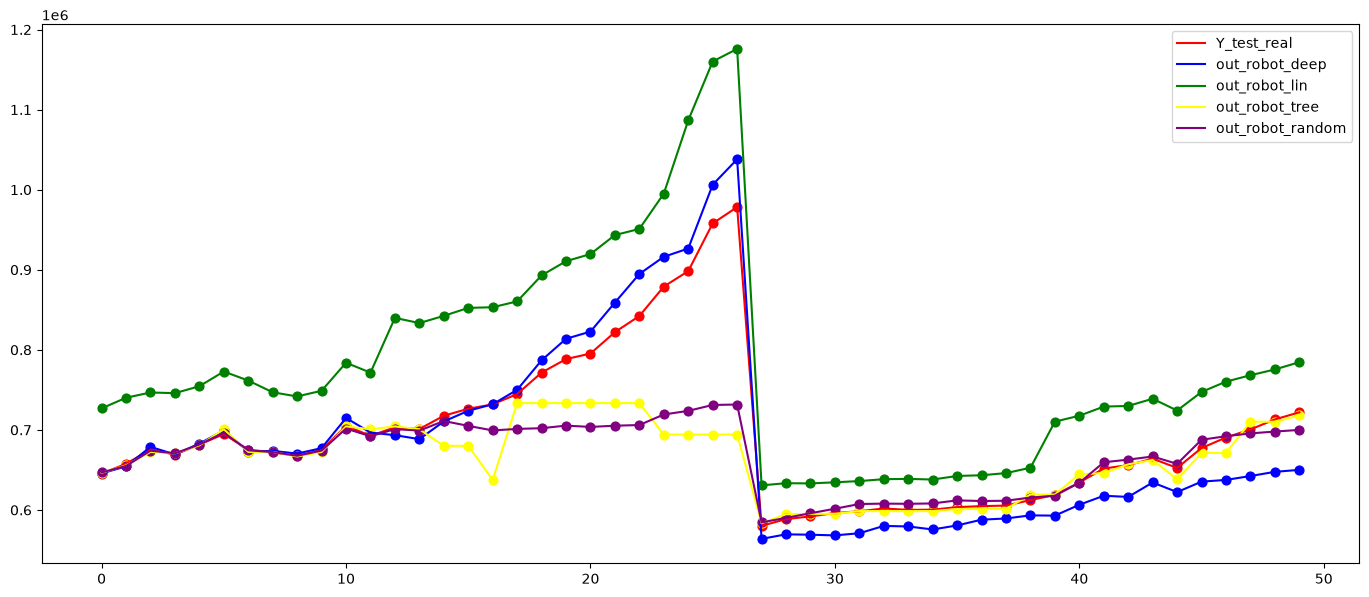

In [49]:
plt.close()
plt.figure(figsize=(17,7))
plt.plot(orgin_y[:50],color='red')
plt.plot(orgin_out[:50],color='blue')
plt.plot(orgin_out_lin[:50],color='green')
plt.plot(orgin_out_tree[:50],color='yellow')
plt.plot(orgin_out_random[:50],color='purple')

plt.scatter(range(50), orgin_y[:50], color='red', s=40)
plt.scatter(range(50), orgin_out[:50], color='blue', s=40)
plt.scatter(range(50), orgin_out_lin[:50], color='green', s=40)
plt.scatter(range(50), orgin_out_tree[:50], color='yellow', s=40)
plt.scatter(range(50), orgin_out_random[:50], color='purple', s=40)

plt.legend(['Y_test_real','out_robot_deep','out_robot_lin','out_robot_tree','out_robot_random'])
plt.show()

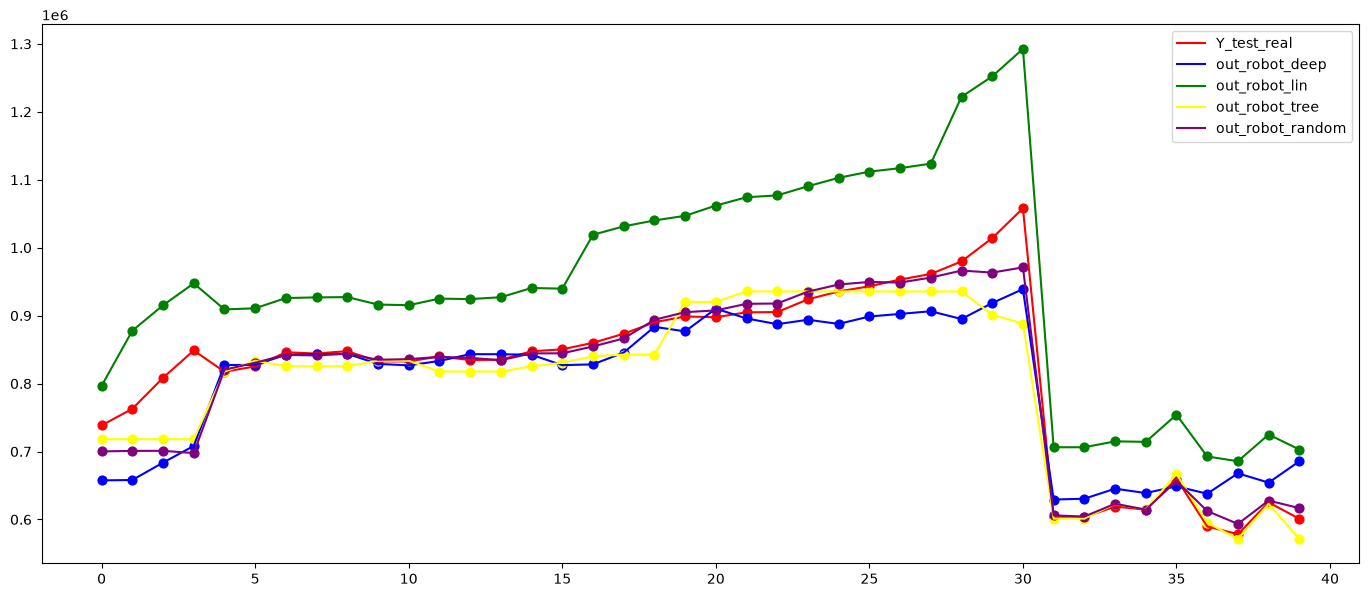

In [50]:
plt.close()
plt.figure(figsize=(17,7))
plt.plot(orgin_y[50:90],color='red')
plt.plot(orgin_out[50:90],color='blue')
plt.plot(orgin_out_lin[50:90],color='green')
plt.plot(orgin_out_tree[50:90],color='yellow')
plt.plot(orgin_out_random[50:90],color='purple')

plt.scatter(range(40), orgin_y[50:90], color='red', s=40)
plt.scatter(range(40), orgin_out[50:90], color='blue', s=40)
plt.scatter(range(40), orgin_out_lin[50:90], color='green', s=40)
plt.scatter(range(40), orgin_out_tree[50:90], color='yellow', s=40)
plt.scatter(range(40), orgin_out_random[50:90], color='purple', s=40)

plt.legend(['Y_test_real','out_robot_deep','out_robot_lin','out_robot_tree','out_robot_random'])
plt.show()

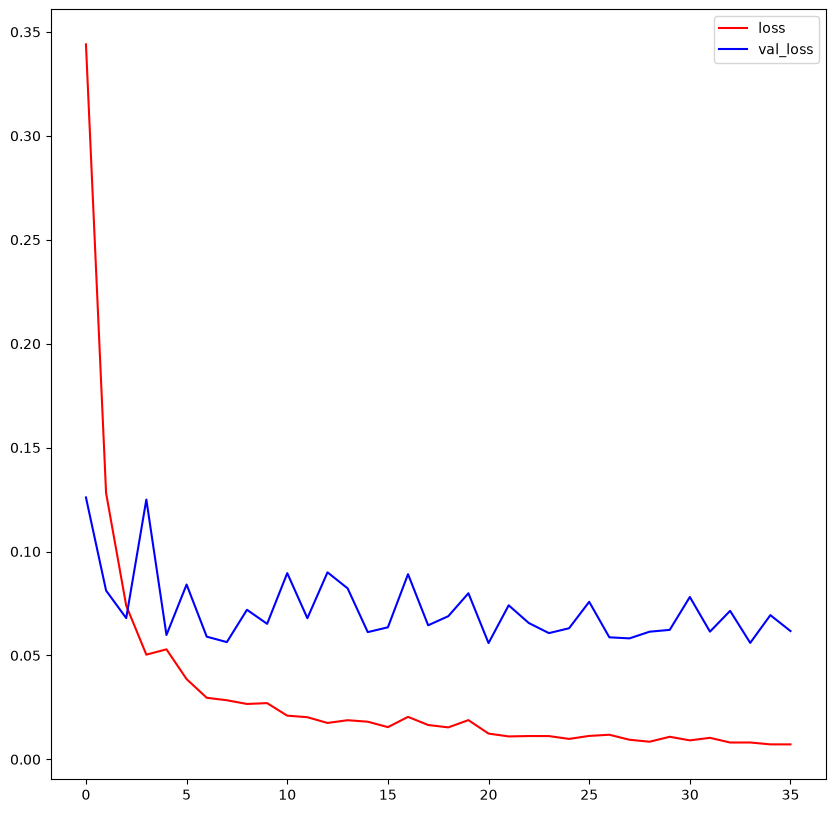

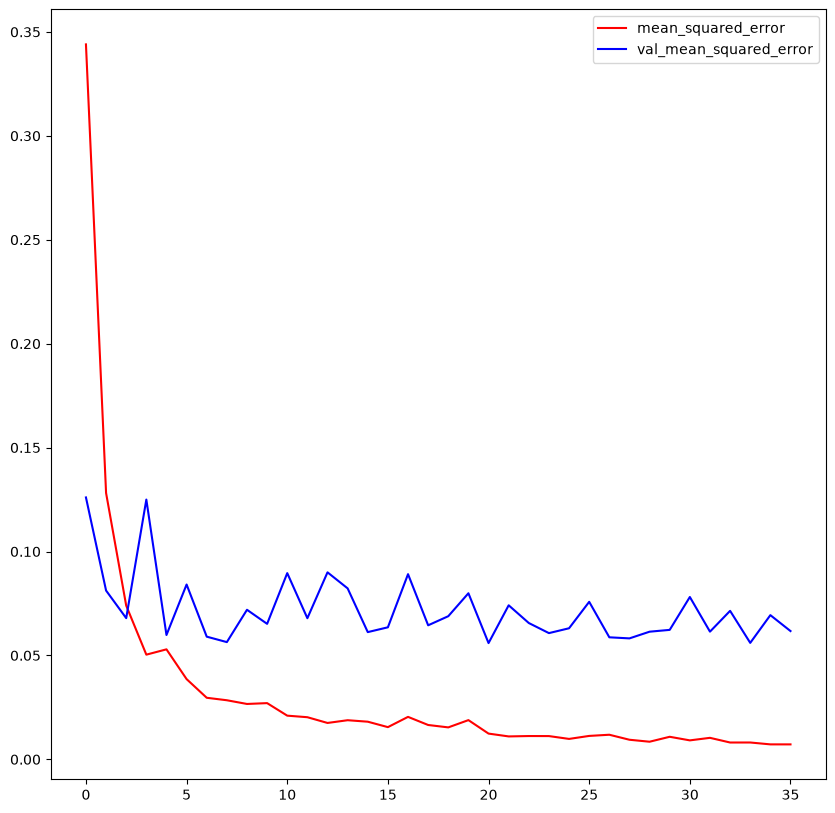

In [51]:
plt.close()
plt.figure(figsize=(10,10))
plt.plot(h.history['loss'],color='red')
plt.plot(h.history['val_loss'],color='blue')
plt.legend(['loss','val_loss'])
plt.show()

plt.close()
plt.figure(figsize=(10,10))
plt.plot(h.history['mean_squared_error'],color='red')
plt.plot(h.history['val_mean_squared_error'],color='blue')
plt.legend(['mean_squared_error','val_mean_squared_error'])
plt.show()

In [315]:
model.save('price_home_canada.h5')

In [55]:
import joblib

joblib.dump(model_random, 'random_forest.joblib')

['random_forest.joblib']